# Chapter 7 · Simulating paths: interactive demos

Companion to Chapter 7 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/07-path-simulation.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider

from mfe230d import bs
from mfe230d.paths import (PiecewiseConstant, brownian_paths, effective_parameters, explained_variance,
                           gbm_paths, gbm_scheme_errors, mse_model, optimal_allocation, term_vol,
                           time_grid)
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. Term structures: average over the step, do not freeze

Under $dS/S=(r(t)-y(t))\,dt+\sigma(t)\,dW$, stepping with the averages of $r$ and $\sigma^2$ over each step is
exact on any grid (Proposition 7.2). Stepping with the values at the left end of each step (the Euler scheme for
$\log S$) is not. Here $y=0$, $r(t)$ is linear and $\sigma(t)$ jumps from $\sigma_1$ to $\sigma_2$ at a switch
time $\tau$. The left panel shows the instantaneous variance $\sigma(t)^2$, the interval forward variances
$\bar\sigma_j^2$ on the grid, and the term variance $\sigma_{0,t}^2$. The right panel prices the one-year
at-the-money call both ways, against the Black--Scholes price with the term parameters.

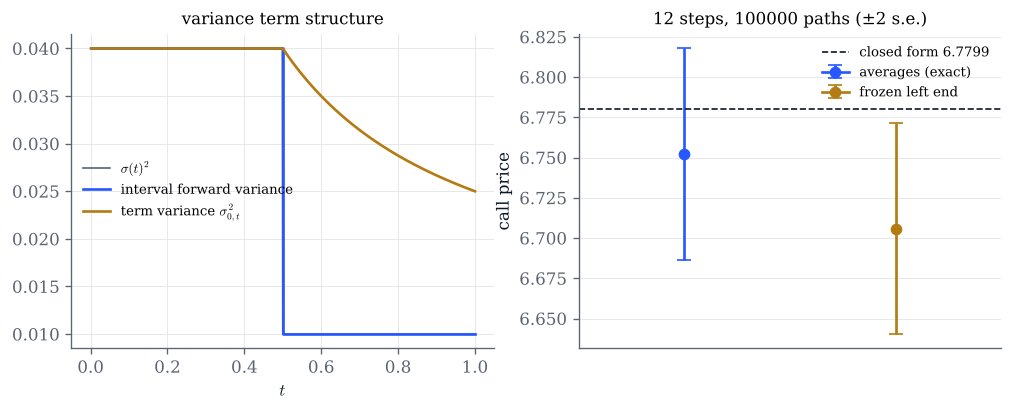

In [2]:
def term_structures(sigma1=0.2, sigma2=0.1, switch=0.5, slope=0.02, n_steps=12, n_paths=100_000, seed=1):
    n_paths = int(n_paths)
    sig = PiecewiseConstant([switch], [sigma1, sigma2])
    rate = lambda u: slope * u
    t = time_grid(1.0, n_steps)
    p = effective_parameters(t, r=rate, sigma=sig)
    fine = np.linspace(0, 1, 801)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(fine, sig(fine) ** 2, color=GREY, lw=1, label="$\\sigma(t)^2$")
    ax.step(t, np.append(p["var"], p["var"][-1]), where="post", color=COBALT, label="interval forward variance")
    ax.plot(fine[1:], term_vol(sig, fine[1:]) ** 2, color=GOLD, label="term variance $\\sigma_{0,t}^2$")
    ax.set(xlabel="$t$", title="variance term structure")
    ax.legend(fontsize=8)

    # exact stepping with averages vs frozen left-end parameters
    disc = np.exp(-slope / 2)                        # exp(-int_0^1 r)
    S = gbm_paths(100.0, t, r=rate, sigma=sig, n_paths=n_paths, seed=seed)
    pay = disc * np.maximum(S[:, -1] - 100, 0)
    left = t[:-1]
    Z = np.random.default_rng(seed).standard_normal((n_paths, n_steps))
    dt = np.diff(t)
    logS = np.log(100) + np.sum((rate(left) - 0.5 * sig(left) ** 2) * dt + sig(left) * np.sqrt(dt) * Z, axis=1)
    pay_f = disc * np.maximum(np.exp(logS) - 100, 0)
    exact = bs.call(100, 100, 1.0, slope / 2, 0.0, np.sqrt(p["clock"][-1]))
    for x, (val, se), color, name in ((0, (pay.mean(), pay.std() / np.sqrt(n_paths)), COBALT, "averages (exact)"),
                                      (1, (pay_f.mean(), pay_f.std() / np.sqrt(n_paths)), GOLD, "frozen left end")):
        ax2.errorbar([x], [val], yerr=[2 * se], color=color, marker="o", capsize=4, label=name)
    ax2.axhline(exact, color=INK, lw=1, ls="--", label=f"closed form {exact:.4f}")
    ax2.set(xlim=(-0.5, 1.5), xticks=[], ylabel="call price", title=f"{n_steps} steps, {n_paths} paths (±2 s.e.)")
    ax2.legend(fontsize=8)
    plt.show()

term_structures()

In [3]:
# Explore: put the switch time between grid dates, or use few steps, and watch the frozen scheme drift away.
interact(term_structures,
         sigma1=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ1"),
         sigma2=FloatSlider(value=0.1, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ2"),
         switch=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.01, continuous_update=False, description="switch τ"),
         slope=FloatSlider(value=0.02, min=-0.05, max=0.1, step=0.005, continuous_update=False, description="r slope"),
         n_steps=IntSlider(value=12, min=1, max=52, continuous_update=False, description="steps"),
         n_paths=FloatLogSlider(value=1e5, base=10, min=3, max=6, step=0.5, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 2. The Brownian bridge construction

The bridge construction samples $W_T$ first, then the midpoint given the two ends, then the quarter points, and so
on (Proposition 7.7). After $2^\ell$ normals the path is exact at the dyadic dates of level $\ell$. The right panel
shows the share of the total variance $\sum_i \mathrm{Var}(W_{t_i})$ carried by the first $k$ normals for the three
constructions; principal components carry the most (Proposition 7.8).

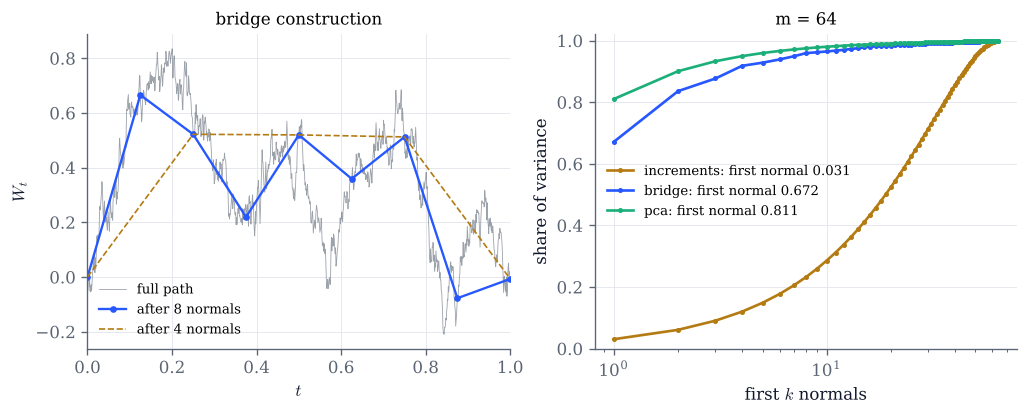

In [4]:
def bridge(level=3, m=64, seed=12):
    K = 10
    t = time_grid(1.0, 2**K)
    W = brownian_paths(t, n_paths=1, seed=seed, method="bridge")[0]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(t, W, color=GREY, lw=0.5, alpha=0.6, label="full path")
    step = 2 ** (K - level)
    ax.plot(t[::step], W[::step], color=COBALT, marker="o", ms=3, lw=1.4, label=f"after {2**level} normals")
    if level > 0:
        prev = 2 ** (K - level + 1)
        ax.plot(t[::prev], W[::prev], color=GOLD, lw=1, ls="--", label=f"after {2**(level-1)} normals")
    ax.set(xlabel="$t$", ylabel="$W_t$", title="bridge construction", xlim=(0, 1))
    ax.legend(fontsize=8)
    tg = time_grid(1.0, m)
    k = np.arange(1, m + 1)
    for method, color in (("increments", GOLD), ("bridge", COBALT), ("pca", GREEN)):
        ev = explained_variance(tg, method)
        ax2.plot(k, ev, color=color, marker="o", ms=2, label=f"{method}: first normal {ev[0]:.3f}")
    ax2.set(xscale="log", xlabel="first $k$ normals", ylabel="share of variance", ylim=(0, 1.02), title=f"m = {m}")
    ax2.legend(fontsize=8)
    plt.show()

bridge()

In [5]:
interact(bridge,
         level=IntSlider(value=3, min=0, max=10, continuous_update=False, description="level ℓ"),
         m=IntSlider(value=64, min=2, max=256, continuous_update=False, description="steps m"),
         seed=IntSlider(value=12, min=0, max=100, continuous_update=False, description="seed"));

## 3. Strong and weak orders of Euler and Milstein

For GBM $dX=\mu X\,dt+\sigma X\,dW$ the exact solution on the same Brownian path is known, so the strong error
$E|X_T-Y^h_T|$ can be measured directly. The weak error $E f(Y^h_T)-E f(X_T)$ is estimated by averaging
$f(Y^h_T)-f(X_T)$ on the same paths, for the smooth payoff $f(x)=5\log(1+e^{(x-100)/5})$. Theorems 7.10 and 7.11
predict slopes $1/2$ (Euler, strong), $1$ (Milstein, strong) and $1$ (both, weak); Richardson extrapolation of
Milstein (Proposition 7.13) has slope $2$. The defaults are the test case.

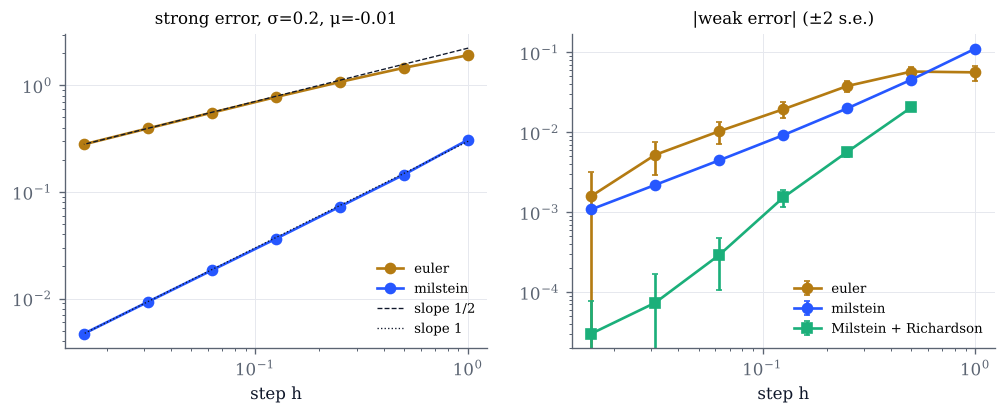

In [6]:
def orders(sigma=0.2, mu=-0.01, n_paths=100_000, seed=2026):
    R = gbm_scheme_errors(mu=mu, sigma=sigma, levels=range(7), n_paths=int(n_paths), seed=seed, chunk=50_000)
    h = R["h"]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    for s, color in (("euler", GOLD), ("milstein", COBALT)):
        ax.plot(h, R["strong"][s], color=color, marker="o", label=s)
        ax2.errorbar(h, np.abs(R["weak"][s]), yerr=2 * R["weak_se"][s], color=color, marker="o", capsize=2, label=s)
    sel = ~np.isnan(R["rich"]["milstein"])
    ax2.errorbar(h[sel], np.abs(R["rich"]["milstein"][sel]), yerr=2 * R["rich_se"]["milstein"][sel], color=GREEN,
                 marker="s", capsize=2, label="Milstein + Richardson")
    ax.plot(h, R["strong"]["euler"][-1] * np.sqrt(h / h[-1]), color=INK, ls="--", lw=0.8, label="slope 1/2")
    ax.plot(h, R["strong"]["milstein"][-1] * h / h[-1], color=INK, ls=":", lw=0.8, label="slope 1")
    ax.set(xscale="log", yscale="log", xlabel="step h", title=f"strong error, σ={sigma}, μ={mu}")
    ax2.set(xscale="log", yscale="log", xlabel="step h", title="|weak error| (±2 s.e.)")
    ax.legend(fontsize=8); ax2.legend(fontsize=8)
    plt.show()

orders()

In [7]:
# Explore: raise σ to make the bias visible; lower the paths to see when noise hides the weak error.
interact(orders,
         sigma=FloatSlider(value=0.2, min=0.05, max=0.8, step=0.05, continuous_update=False, description="σ"),
         mu=FloatSlider(value=-0.01, min=-0.2, max=0.3, step=0.01, continuous_update=False, description="μ"),
         n_paths=FloatLogSlider(value=1e5, base=10, min=3, max=5.7, step=0.1, continuous_update=False, description="paths"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 4. Time steps or paths?

With bias $c\,h^\beta$, payoff variance $v$ and a budget of $C$ steps, the mean-square error of $n=C/m$ paths with
$m$ steps is $c^2(1/m)^{2\beta}+v\,m/C$ (Proposition 7.14). The optimum balances the two: the variance is $2\beta$
times the squared bias. The defaults are the measured Euler constants of the notes ($c=0.17$, $v=154$).

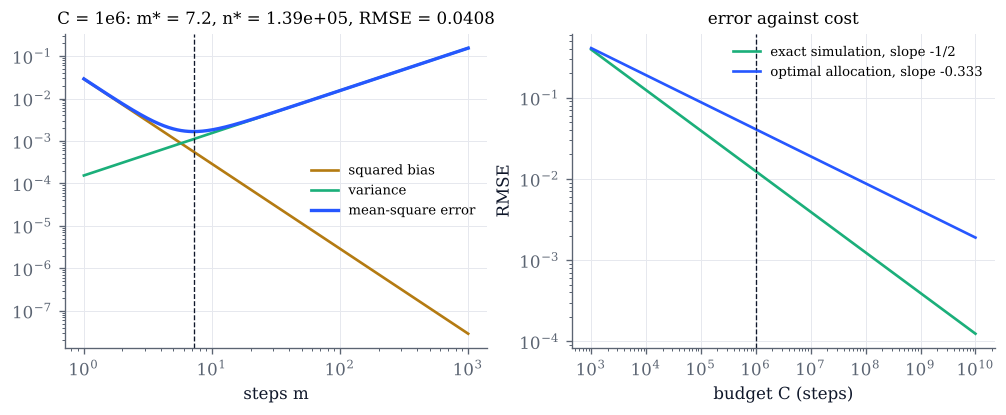

In [8]:
def allocation(log10_budget=6.0, c=0.17, v=154.0, beta=1.0):
    C = 10.0**log10_budget
    m = np.geomspace(1, 1000, 400)
    opt = optimal_allocation(C, c, v, beta=beta)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(m, c**2 * m ** (-2 * beta), color=GOLD, label="squared bias")
    ax.plot(m, v * m / C, color=GREEN, label="variance")
    ax.plot(m, mse_model(m, C, c, v, beta=beta), color=COBALT, lw=2, label="mean-square error")
    ax.axvline(opt["m"], color=INK, ls="--", lw=0.8)
    ax.set(xscale="log", yscale="log", xlabel="steps m",
           title=f"C = 1e{log10_budget:g}: m* = {opt['m']:.1f}, n* = {opt['n']:.3g}, RMSE = {opt['rmse']:.3g}")
    ax.legend(fontsize=8)
    budgets = np.geomspace(1e3, 1e10, 50)
    ax2.plot(budgets, np.sqrt(v / budgets), color=GREEN, label="exact simulation, slope -1/2")
    ax2.plot(budgets, [optimal_allocation(b, c, v, beta=beta)["rmse"] for b in budgets], color=COBALT,
             label=f"optimal allocation, slope -{beta / (2 * beta + 1):.3f}")
    ax2.axvline(C, color=INK, ls="--", lw=0.8)
    ax2.set(xscale="log", yscale="log", xlabel="budget C (steps)", ylabel="RMSE", title="error against cost")
    ax2.legend(fontsize=8)
    plt.show()

allocation()

In [9]:
interact(allocation,
         log10_budget=FloatSlider(value=6, min=3, max=10, step=0.25, continuous_update=False, description="log10 C"),
         c=FloatLogSlider(value=0.17, base=10, min=-3, max=1, step=0.05, continuous_update=False, description="bias c"),
         v=FloatLogSlider(value=154, base=10, min=0, max=4, step=0.05, continuous_update=False, description="variance v"),
         beta=FloatSlider(value=1.0, min=0.5, max=3.0, step=0.5, continuous_update=False, description="order β"));

## Things to try

- In section 1, set the switch time to $0.54$ with 12 steps. Both the frozen scheme's error and its sign change;
  why does the averaged scheme not care where the switch falls?
- In section 2, find the level $\ell$ after which the bridge path stops changing visibly. How many normals is that,
  out of $1024$?
- In section 3, set $\sigma=0.8$. Which of the four slopes survive, and at which step sizes does the asymptotic
  regime start?
- In section 4, set $\beta=2$ (an extrapolated scheme) and compare the optimal number of steps with $\beta=1$ at the
  same budget. Why does a higher order call for fewer steps and more paths?